In [1]:
!pip install pandas numpy matplotlib seaborn scikit-learn joblib

Defaulting to user installation because normal site-packages is not writeable


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)
print("Libraries imported successfully")

Libraries imported successfully


In [8]:
application_train = pd.read_csv("application_train.csv")
bureau = pd.read_csv("bureau.csv")
bureau_balance = pd.read_csv("bureau_balance.csv")
pos_cash = pd.read_csv("POS_CASH_balance.csv")
credit_card = pd.read_csv("credit_card_balance.csv")
previous_application = pd.read_csv("previous_application.csv")
installments = pd.read_csv("installments_payments.csv")
print("All datasets loaded successfully")

All datasets loaded successfully


In [9]:
datasets = {
    "Application Train": application_train,
    "Bureau": bureau,
    "Bureau Balance": bureau_balance,
    "POS Cash": pos_cash,
    "Credit Card": credit_card,
    "Previous Application": previous_application,
    "Installments": installments
}
for name, df in datasets.items():
    print(name, ":", df.shape)

Application Train : (307511, 122)
Bureau : (1716428, 17)
Bureau Balance : (27299925, 3)
POS Cash : (10001358, 8)
Credit Card : (3840312, 23)
Previous Application : (1670214, 37)
Installments : (13605401, 8)


### Task 1

In [10]:
application_train.head()

,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,...,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,...,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.650442,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single /

In [11]:
application_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float64(65), int64(41), object(16)
memory usage: 286.2+ MB


In [12]:
application_train.describe()

,SK_ID_CURR,TARGET,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,FLOORSMIN_AVG,LANDAREA_AVG,LIVINGAPARTMENTS_AVG,LIVINGAREA_AVG,NONLIVINGAPARTMENTS_AVG,NONLIVINGAREA_AVG,APARTMENTS_MODE,BASEMENTAREA_MODE,YEARS_BEGINEXPLUATATION_MODE,YEARS_BUILD_MODE,...,LIVINGAPARTMENTS_MODE,LIVINGAREA_MODE,NONLIVINGAPARTMENTS_MODE,NONLIVINGAREA_MODE,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,TOTALAREA_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
count,307511.000000,307511.000000,307511.000000,3.075110e+05,3.075110e+05,307499.000000,3.072330e+05,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,104582.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307509.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,134133.000000,3.068510e+05,246546.000000,151450.00000,127568.000000,157504.000000,103023.000000,92646.000000,143620.000000,152683.000000,154491.000000,98869.000000,124921.000000,97312.000000,153161.000000,93997.000000,137829.000000,151450.000000,127568.000000,157504.000000,103023.000000,...,97312.000000,153161.000000,93997.000000,137829.000000,151450.000000,127568.000000,157504.000000,103023.000000,92646.000000,143620.000000,152683.000000,154491.000000,98869.000000,124921.000000,97312.000000,153161.000000,93997.000000,137829.000000,159080.000000,306490.000000,306490.000000,306490.000000,306490.000000,307510.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.00000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,307511.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000,265992.000000
mean,278180.518577,0.080729,0.417052,1.687979e+05,5.990260e+05,27108.573909,5.383962e+05,0.020868,-16036.995067,63815.045904,-4986.120328,-2994.202373,12.061091,0.999997,0.819889,0.199368,0.998133,0.281066,0.056720,2.152665,2.052463,2.031521,12.063419,0.015144,0.050769,0.040659,0.078173,0.230454,0.179555,0.502130,5.143927e-01,0.510853,0.11744,0.088442,0.977735,0.752471,0.044621,0.078942,0.149725,0.226282,0.231894,0.066333,0.100775,0.107399,0.008809,0.028358,0.114231,0.087543,0.977065,0.759637,...,0.105645,0.105975,0.008076,0.027022,0.117850,0.087955,0.977752,0.755746,0.044595,0.078078,0.149213,0.225897,0.231625,0.067169,0.101954,0.108607,0.008651,0.028236,0.102547,1.422245,0.143421,1.405292,0.100049,-962.858788,0.000042,0.710023,0.000081,0.015115,0.088055,0.000192

In [13]:
missing_values = application_train.isnull().sum()
missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(application_train)
    ) * 100
})
missing_report = missing_report.sort_values(
    by="Missing Percentage",
    ascending=False
)
missing_report.head(30)

,Missing Values,Missing Percentage
COMMONAREA_MEDI,214865,69.872297
COMMONAREA_AVG,214865,69.872297
COMMONAREA_MODE,214865,69.872297
NONLIVINGAPARTMENTS_MODE,213514,69.432963
NONLIVINGAPARTMENTS_AVG,213514,69.432963
NONLIVINGAPARTMENTS_MEDI,213514,69.432963
FONDKAPREMONT_MODE,210295,68.386172
LIVINGAPARTMENTS_MODE,210199,68.354953
LIVINGAPARTMENTS_AVG,210199,68.354953
LIVINGAPARTMENTS_MEDI,210199,68.354953


In [14]:
print("Duplicate records:",
      application_train.duplicated().sum())

Duplicate records: 0


TARGET
0    282686
1     24825
Name: count, dtype: int64


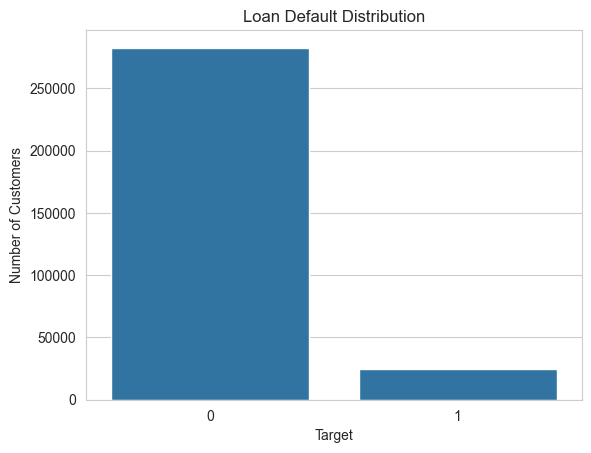

In [15]:
print(application_train["TARGET"].value_counts())
sns.countplot(data=application_train, x="TARGET")
plt.title("Loan Default Distribution")
plt.xlabel("Target")
plt.ylabel("Number of Customers")
plt.show()

In [16]:
target_percentage = (
    application_train["TARGET"].value_counts(normalize=True) * 100
)
print(target_percentage)

TARGET
0    91.927118
1     8.072882
Name: proportion, dtype: float64


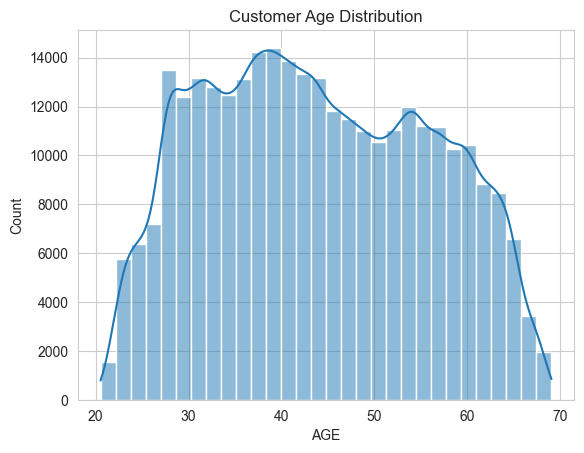

In [17]:
application_train["AGE"] = (
    -application_train["DAYS_BIRTH"] / 365
)
sns.histplot(
    data=application_train,
    x="AGE",
    bins=30,
    kde=True
)
plt.title("Customer Age Distribution")
plt.show()

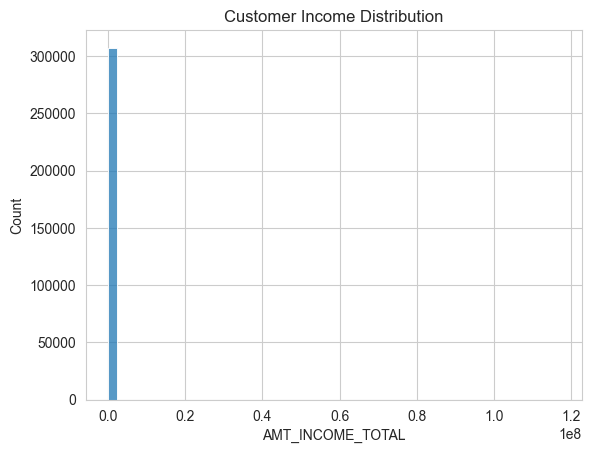

In [18]:
sns.histplot(
    data=application_train,
    x="AMT_INCOME_TOTAL",
    bins=50
)
plt.title("Customer Income Distribution")
plt.show()

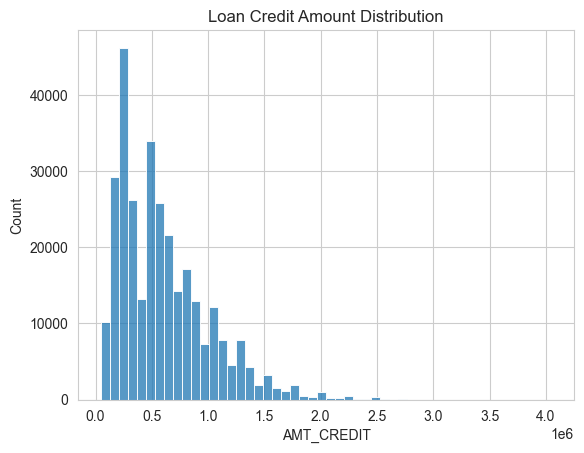

In [19]:
sns.histplot(
    data=application_train,
    x="AMT_CREDIT",
    bins=50
)
plt.title("Loan Credit Amount Distribution")
plt.show()

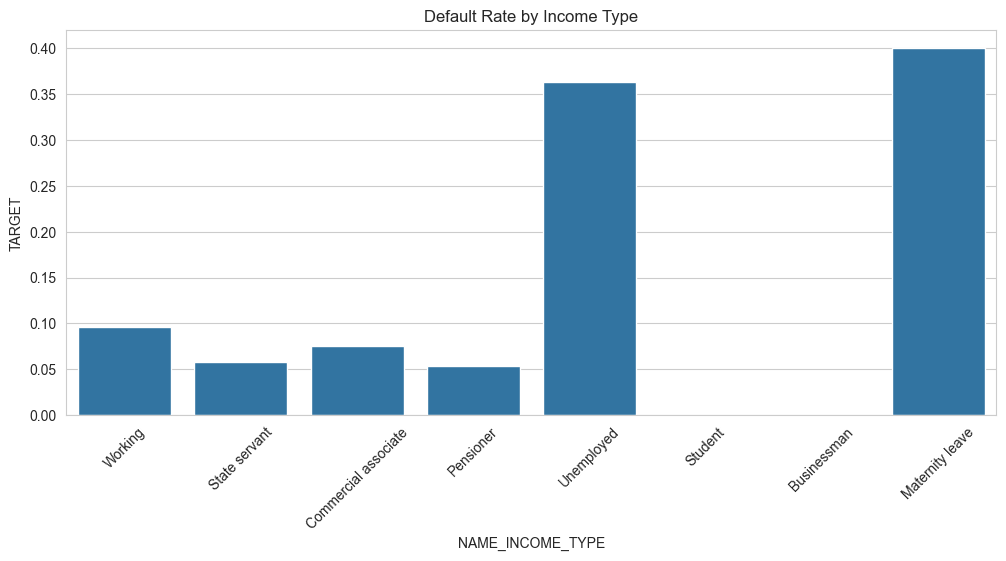

In [20]:
plt.figure(figsize=(12, 5))
sns.barplot(
    data=application_train,
    x="NAME_INCOME_TYPE",
    y="TARGET",
    errorbar=None
)
plt.xticks(rotation=45)
plt.title("Default Rate by Income Type")
plt.show()

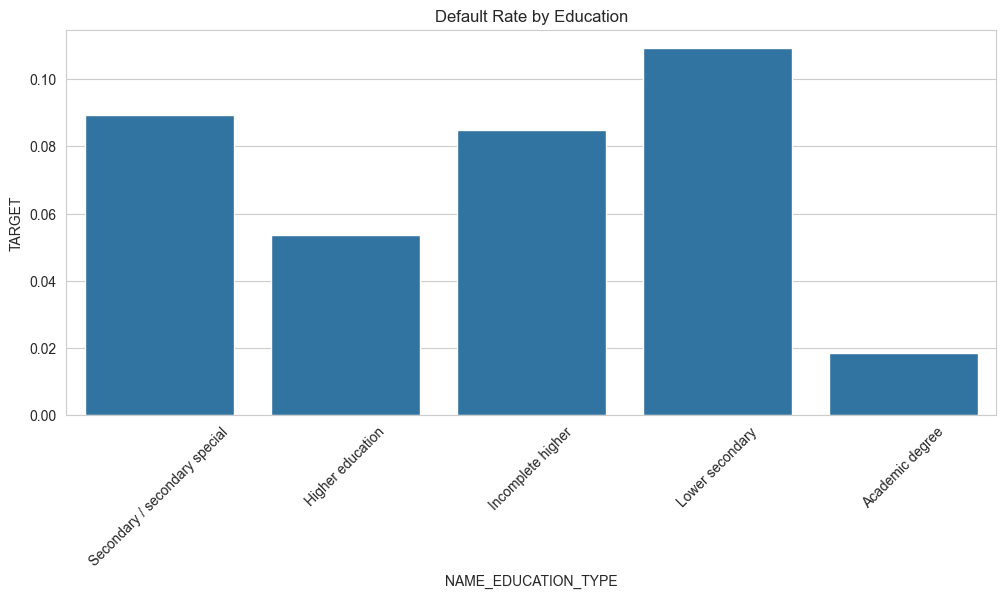

In [21]:
plt.figure(figsize=(12, 5))
sns.barplot(
    data=application_train,
    x="NAME_EDUCATION_TYPE",
    y="TARGET",
    errorbar=None
)
plt.xticks(rotation=45)
plt.title("Default Rate by Education")
plt.show()

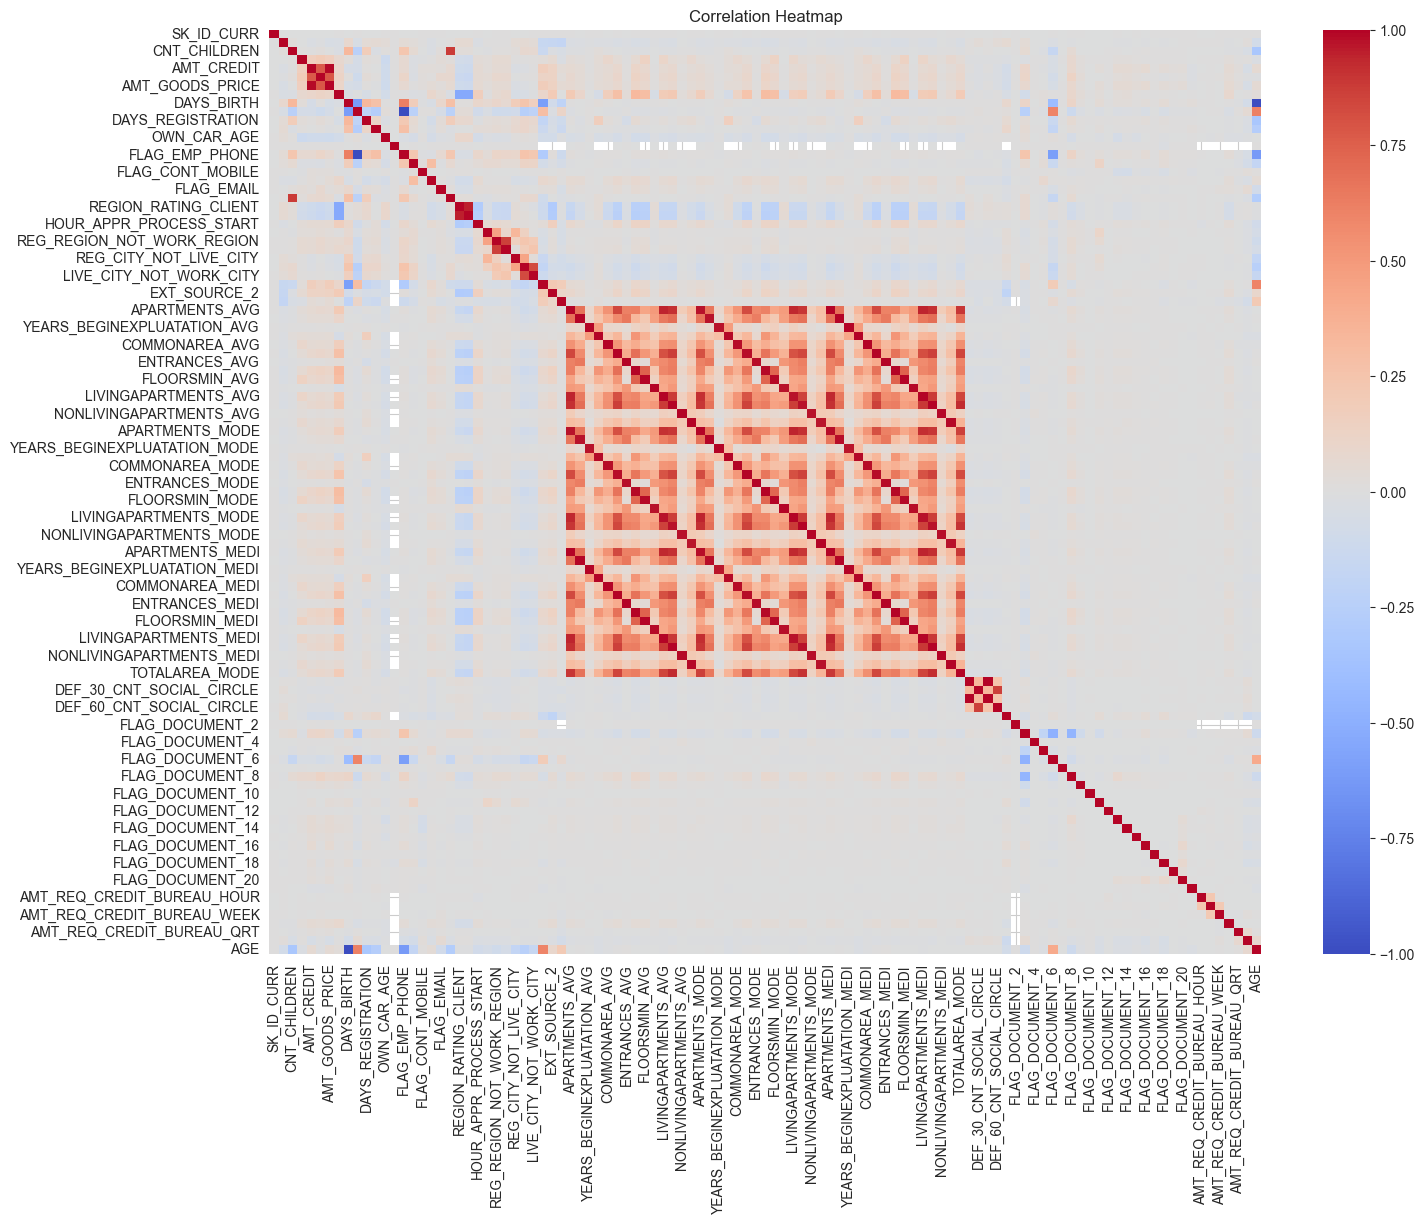

In [22]:
numeric_data = application_train.select_dtypes(
    include=np.number
)
correlation = numeric_data.corr()
plt.figure(figsize=(16, 12))
sns.heatmap(
    correlation,
    cmap="coolwarm",
    center=0
)
plt.title("Correlation Heatmap")
plt.show()

In [23]:
for name, df in datasets.items():
    print("\nDataset:", name)
    print("Shape:", df.shape)
    print("Missing values:", df.isnull().sum().sum())
    print("Duplicate rows:", df.duplicated().sum())
    print(df.head(3))


Dataset: Application Train
Shape: (307511, 123)
Missing values: 9152465
Duplicate rows: 0
   SK_ID_CURR  TARGET NAME_CONTRACT_TYPE CODE_GENDER FLAG_OWN_CAR  \
0      100002       1         Cash loans           M            N   
1      100003       0         Cash loans           F            N   
2      100004       0    Revolving loans           M            Y   

  FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  \
0               Y             0          202500.0    406597.5      24700.5   
1               N             0          270000.0   1293502.5      35698.5   
2               Y             0           67500.0    135000.0       6750.0   

   AMT_GOODS_PRICE NAME_TYPE_SUITE NAME_INCOME_TYPE  \
0         351000.0   Unaccompanied          Working   
1        1129500.0          Family    State servant   
2         135000.0   Unaccompanied          Working   

             NAME_EDUCATION_TYPE    NAME_FAMILY_STATUS  NAME_HOUSING_TYPE  \
0  Secondary / second

In [25]:
print("TASK 1 - DATA ANALYSIS SUMMARY")
print("Total Customers:", len(application_train))
print("Customers with Payment Difficulties:",(application_train["TARGET"] == 1).sum())
print("Customers without Payment Difficulties:",(application_train["TARGET"] == 0).sum())
print("Default Percentage:",round(application_train["TARGET"].mean() * 100, 2), "%")
print("Total Missing Values:",application_train.isnull().sum().sum())
print("Duplicate Records:",application_train.duplicated().sum())

TASK 1 - DATA ANALYSIS SUMMARY
Total Customers: 307511
Customers with Payment Difficulties: 24825
Customers without Payment Difficulties: 282686
Default Percentage: 8.07 %
Total Missing Values: 9152465
Duplicate Records: 0


### Task 2

In [70]:
from sklearn.linear_model import LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix
from sklearn.metrics import roc_curve
from sklearn.inspection import permutation_importance
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

In [71]:
def aggregate_numeric(df, group_column, prefix):
    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns.tolist()
    exclude_columns = [
        group_column,
        "SK_ID_BUREAU",
        "SK_ID_PREV",
        "SK_ID_CURR"
    ]
    numeric_columns = [
        col for col in numeric_columns
        if col not in exclude_columns
    ]
    if len(numeric_columns) == 0:
        return df[[group_column]].drop_duplicates()
    aggregation = df.groupby(group_column)[
        numeric_columns
    ].agg(["mean", "max", "min", "sum"])
    aggregation.columns = [
        prefix + "_" + col + "_" + stat
        for col, stat in aggregation.columns
    ]
    return aggregation.reset_index()

In [72]:
bureau_balance_agg = bureau_balance.groupby(
    "SK_ID_BUREAU"
).agg(
    BB_MONTHS_MEAN=("MONTHS_BALANCE", "mean"),
    BB_MONTHS_MIN=("MONTHS_BALANCE", "min"),
    BB_MONTHS_MAX=("MONTHS_BALANCE", "max"),
    BB_STATUS_COUNT=("STATUS", "count"),
    BB_STATUS_UNIQUE=("STATUS", "nunique")
).reset_index()
bureau_with_balance = bureau.merge(
    bureau_balance_agg,
    on="SK_ID_BUREAU",
    how="left"
)
bureau_agg = aggregate_numeric(
    bureau_with_balance,
    "SK_ID_CURR",
    "BUREAU"
)

In [73]:
previous_agg = aggregate_numeric(
    previous_application,
    "SK_ID_CURR",
    "PREVIOUS"
)

In [74]:
pos_agg = aggregate_numeric(
    pos_cash,
    "SK_ID_CURR",
    "POS"
)

In [75]:
credit_card_agg = aggregate_numeric(
    credit_card,
    "SK_ID_CURR",
    "CREDIT_CARD"
)

In [76]:
installments_agg = aggregate_numeric(
    installments,
    "SK_ID_CURR",
    "INSTALLMENTS"
)

In [82]:
def reduce_memory(df):
    for col in df.columns:
        if df[col].dtype == "float64":
            df[col] = df[col].astype("float32")
        elif df[col].dtype == "int64":
            df[col] = pd.to_numeric(df[col],downcast="integer")
    return df

In [81]:
application_train = reduce_memory(application_train)
bureau_agg = reduce_memory(bureau_agg)
previous_agg = reduce_memory(previous_agg)
pos_agg = reduce_memory(pos_agg)
credit_card_agg = reduce_memory(credit_card_agg)
installments_agg = reduce_memory(installments_agg)

print("Memory optimization completed")

Memory optimization completed


In [83]:
model_data = application_train.copy()
aggregated_datasets = [
    bureau_agg,
    previous_agg,
    pos_agg,
    credit_card_agg,
    installments_agg
]
for df in aggregated_datasets:
    model_data = model_data.merge(
        df,
        on="SK_ID_CURR",
        how="left"
    )
print("Merged dataset shape:", model_data.shape)

Merged dataset shape: (307511, 391)


In [84]:
X = model_data.drop(columns=["TARGET", "SK_ID_CURR"],errors="ignore")
y = model_data["TARGET"]
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (307511, 389)
Target shape: (307511,)


In [85]:
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 373
Categorical features: 16


In [86]:
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore"))])
preprocessor = ColumnTransformer([("num", numeric_pipeline, numeric_features),("cat", categorical_pipeline, categorical_features)])

In [87]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (246008, 389)
Testing data: (61503, 389)


In [88]:
print("Preprocessor:", "preprocessor" in globals())
print("X_train:", "X_train" in globals())
print("y_train:", "y_train" in globals())
print("X_test:", "X_test" in globals())

Preprocessor: True
X_train: True
y_train: True
X_test: True


In [89]:
import pandas as pd
import numpy as np
selected_columns = [
    "TARGET",
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "CNT_CHILDREN",
    "CNT_FAM_MEMBERS",
    "REGION_RATING_CLIENT",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS"
]
data = application_train[selected_columns].copy()
print(data.shape)

(307511, 17)


In [90]:
X = data.drop(columns=["TARGET"])
y = data["TARGET"]
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

In [91]:
numeric_pipeline = Pipeline([("imputer", SimpleImputer(strategy="median")),("scaler", StandardScaler())])
categorical_pipeline = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),("encoder", OneHotEncoder(handle_unknown="ignore",sparse_output=True,dtype=np.float32,min_frequency=100))])
preprocessor = ColumnTransformer(transformers=[("num", numeric_pipeline, numeric_features),("cat", categorical_pipeline, categorical_features)],sparse_threshold=1.0)

In [92]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("Training:", X_train.shape)
print("Testing:", X_test.shape)

Training: (246008, 16)
Testing: (61503, 16)


In [93]:
lr_model = Pipeline([("preprocessor", preprocessor),("classifier", LogisticRegression(solver="saga",max_iter=100,class_weight="balanced",random_state=42,tol=0.001))])
lr_model.fit(X_train, y_train)
lr_predictions = lr_model.predict(X_test)
lr_probabilities = lr_model.predict_proba(X_test)[:, 1]
print("Logistic Regression completed successfully!")

Logistic Regression completed successfully!


In [94]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("Accuracy:", accuracy_score(y_test, lr_predictions))
print("Precision:", precision_score(y_test, lr_predictions))
print("Recall:", recall_score(y_test, lr_predictions))
print("F1 Score:", f1_score(y_test, lr_predictions))
print("ROC-AUC:", roc_auc_score(y_test, lr_probabilities))

Accuracy: 0.6800969058419915
Precision: 0.15472725565674583
Recall: 0.6638469284994964
F1 Score: 0.25096128221723074
ROC-AUC: 0.7317863553488093


In [95]:
rf_model = Pipeline([("preprocessor", preprocessor),("classifier", RandomForestClassifier(n_estimators=100,max_depth=15,min_samples_leaf=3,class_weight="balanced_subsample",random_state=42,n_jobs=-1))])
rf_model.fit(X_train, y_train)
rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]
print("Random Forest completed")

Random Forest completed


In [96]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)
def evaluate_model(name, y_true, predictions, probabilities):
    print("\n", name)
    print("Accuracy:",accuracy_score(y_true, predictions))
    print("Precision:",precision_score(y_true, predictions, zero_division=0))
    print("Recall:",recall_score(y_true, predictions, zero_division=0))
    print("F1 Score:",f1_score(y_true, predictions, zero_division=0))
    print("ROC-AUC:",roc_auc_score(y_true, probabilities))
    print("PR-AUC:",average_precision_score(y_true, probabilities))
evaluate_model("Logistic Regression",y_test,lr_predictions,lr_probabilities)
evaluate_model("Random Forest",y_test,rf_predictions,rf_probabilities)


 Logistic Regression
Accuracy: 0.6800969058419915
Precision: 0.15472725565674583
Recall: 0.6638469284994964
F1 Score: 0.25096128221723074
ROC-AUC: 0.7317863553488093
PR-AUC: 0.21243260842139894

 Random Forest
Accuracy: 0.8013105051786091
Precision: 0.19687473886521267
Recall: 0.47452165156092646
F1 Score: 0.27828962910465393
ROC-AUC: 0.7348923877877749
PR-AUC: 0.21583223142463007


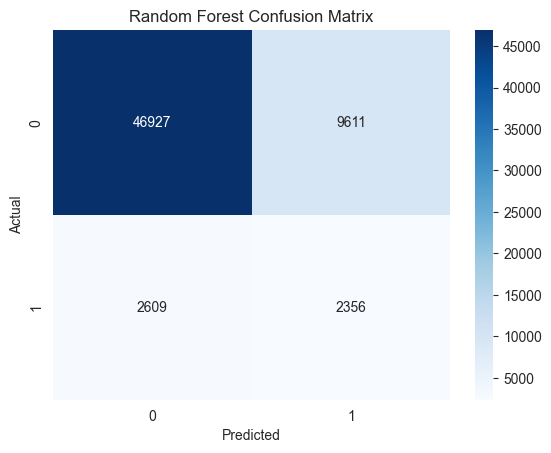

In [105]:
cm = confusion_matrix(y_test, rf_predictions)
sns.heatmap(cm,annot=True,fmt="d",cmap="Blues")
plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

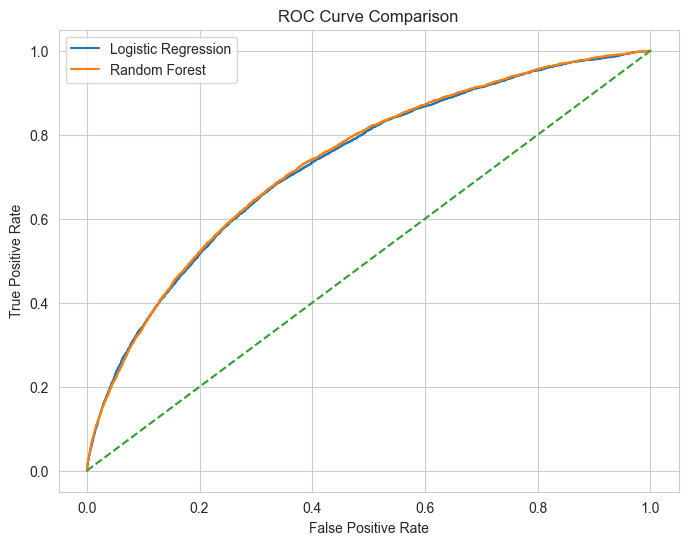

In [106]:
lr_fpr, lr_tpr, _ = roc_curve(y_test, lr_probabilities)
rf_fpr, rf_tpr, _ = roc_curve(y_test, rf_probabilities)
plt.figure(figsize=(8, 6))
plt.plot(lr_fpr, lr_tpr, label="Logistic Regression")
plt.plot(rf_fpr, rf_tpr, label="Random Forest")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()
plt.show()

In [107]:
importance = permutation_importance(
    rf_model,
    X_test,
    y_test,
    n_repeats=2,
    random_state=42,
    scoring="roc_auc",
    n_jobs=1
)
feature_importance = pd.DataFrame({"Feature": X_test.columns,"Importance": importance.importances_mean})
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)
display(feature_importance.head(20))

,Feature,Importance
10,EXT_SOURCE_3,0.065232
9,EXT_SOURCE_2,0.046931
14,NAME_EDUCATION_TYPE,0.014631
3,AMT_GOODS_PRICE,0.012704
4,DAYS_BIRTH,0.009451
5,DAYS_EMPLOYED,0.009450
11,NAME_CONTRACT_TYPE,0.008230
12,CODE_GENDER,0.005687
2,AMT_ANNUITY,0.005523
1,AMT_CREDIT,0.004879


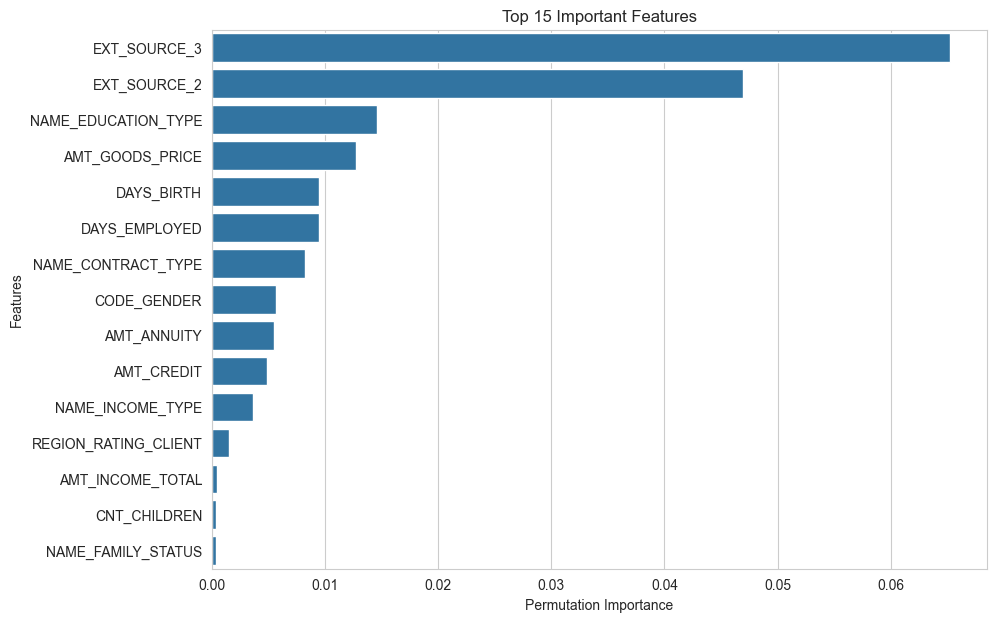

In [108]:
top_features = feature_importance.head(15)
plt.figure(figsize=(10, 7))
sns.barplot(data=top_features,x="Importance",y="Feature")
plt.title("Top 15 Important Features")
plt.xlabel("Permutation Importance")
plt.ylabel("Features")
plt.show()

In [109]:
risk_results = pd.DataFrame({"Actual Target": y_test.values,"Default Probability": rf_probabilities})
def classify_risk(probability):
    if probability < 0.10:
        return "Low Risk"
    elif probability < 0.30:
        return "Medium Risk"
    else:
        return "High Risk"
risk_results["Risk Category"] = (risk_results["Default Probability"].apply(classify_risk))
display(risk_results.head(20))

,Actual Target,Default Probability,Risk Category
0,0,0.415583,High Risk
1,0,0.331838,High Risk
2,0,0.559293,High Risk
3,0,0.312900,High Risk
4,0,0.457901,High Risk
5,0,0.592096,High Risk
6,0,0.054297,Low Risk
7,0,0.106459,Medium Risk
8,0,0.748854,High Risk
9,1,0.254152,Medium Risk


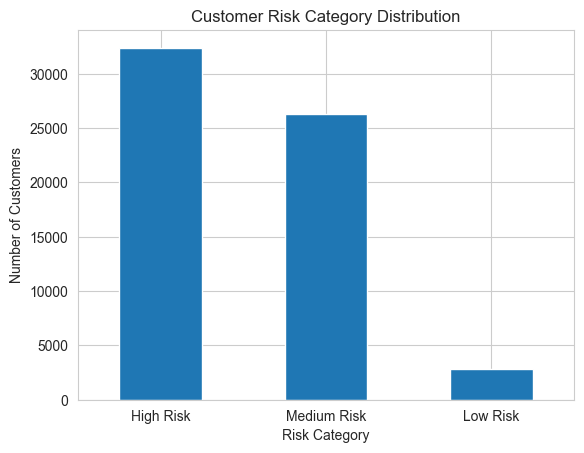

In [110]:
risk_results["Risk Category"].value_counts().plot(kind="bar")
plt.title("Customer Risk Category Distribution")
plt.xlabel("Risk Category")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [111]:
joblib.dump(rf_model, "loan_default_prediction_model.pkl")
print("Model saved successfully")

Model saved successfully


In [112]:
loaded_model = joblib.load("loan_default_prediction_model.pkl")
sample_data = X_test.iloc[[0]]
prediction = loaded_model.predict(sample_data)
probability = loaded_model.predict_proba(sample_data)[0][1]
print("Predicted Class:", prediction[0])
print("Default Probability:", round(probability * 100, 2), "%")

Predicted Class: 0
Default Probability: 41.56 %



# MODEL COMPARISON REPORT
## Home Credit Loan Default Risk Prediction

### 1. Introduction

The objective of this project is to develop and compare different Machine Learning models to predict the possibility of loan repayment difficulties among customers.

Two Machine Learning algorithms were implemented:
1. Logistic Regression
2. Random Forest Classifier

### 2. Models Used

**Logistic Regression:**

Logistic Regression is a classification algorithm used to predict whether a customer is likely to experience loan repayment difficulties. It provides a simple baseline model and is relatively easy to interpret.

**Random Forest Classifier:**

Random Forest is an ensemble learning algorithm that combines multiple decision trees to improve prediction performance. It can identify complex relationships between customer financial information and loan default risk.

### 3. Evaluation Metrics

The following metrics were used to compare model performance:

- Accuracy: Measures the overall percentage of correct predictions.
- Precision: Measures how many predicted defaulters were actually defaulters.
- Recall: Measures how many actual defaulters were correctly identified.
- F1 Score: Balances precision and recall.
- ROC-AUC: Measures how well the model distinguishes between defaulters and non-defaulters.
- PR-AUC: Measures precision-recall performance, particularly useful for imbalanced datasets.

### 4. Model Comparison

Both Logistic Regression and Random Forest were evaluated using the same training and testing data.

The performance results are displayed in the model comparison table generated in the following code cell.

### 5. Best Model Selection

The best-performing model is selected based on ROC-AUC, PR-AUC, recall, and precision rather than accuracy alone.

Random Forest can be considered a suitable candidate if it demonstrates stronger predictive performance. Logistic Regression is useful as an interpretable baseline model.

### 6. Recommendation for Production

The selected model should undergo additional validation before production deployment. This includes probability calibration, threshold selection, fairness assessment, and testing on newer customer data.

The model should support loan risk assessment and should not independently make final loan approval or rejection decisions.

### 7. Conclusion

The comparison of Logistic Regression and Random Forest helps identify a suitable Machine Learning algorithm for predicting loan default risk. The final model should be selected based on actual evaluation results and business requirements.


In [116]:
display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC,PR-AUC
0,Logistic Regression,0.6801,0.1547,0.6638,0.2510,0.7318,0.2124
1,Random Forest,0.8013,0.1969,0.4745,0.2783,0.7349,0.2158


In [117]:
best_model_name = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
).iloc[0]["Model"]

print("Best model based on ROC-AUC:", best_model_name)

Best model based on ROC-AUC: Random Forest



# REPORT ON CHALLENGES FACED
## Home Credit Loan Default Risk Prediction

### 1. Introduction

During this project, several challenges were encountered while performing data analysis, data preprocessing, feature engineering, and Machine Learning model development.

The project involved a large financial dataset containing customer information, loan details, previous applications, credit history, and payment records.

The following sections explain the major challenges and the techniques used to overcome them.

### 2. Challenges and Solutions

**Challenge 1: Missing Values**

The datasets contained missing values in several numerical and categorical columns.

**Technique Used:** Median imputation was applied to numerical columns, and mode imputation was applied to categorical columns.

**Reason:** These techniques help handle incomplete data while retaining useful customer records.

**Challenge 2: Duplicate Records**

Duplicate records can affect the accuracy of data analysis and model development.

**Technique Used:** Duplicate records were identified using the duplicated() function and removed where appropriate.

**Reason:** Removing unnecessary duplicate observations helps prevent repeated records from influencing the analysis.

**Challenge 3: Imbalanced Target Variable**

The dataset contained more non-defaulter customers than defaulter customers.

**Technique Used:** Class weighting and stratified train-test splitting were used.

**Reason:** These techniques help the model account for the minority class and preserve the target distribution in training and testing data.

**Challenge 4: Large Dataset Size**

The project contained multiple supporting datasets, including bureau, previous applications, credit card, POS cash, and installment payment records.

**Technique Used:** Dataset aggregation, feature selection, and memory optimization were considered.

**Reason:** These techniques reduce unnecessary columns and memory consumption during data processing.

**Challenge 5: Memory Error During Dataset Merging**

Merging multiple large datasets caused memory allocation errors.

**Technique Used:** The main application dataset was used as a baseline for model development, and unnecessary large merges were avoided.

**Reason:** This reduced RAM consumption and allowed model training to proceed with fewer features.

**Challenge 6: High Number of Categorical Features**

One-Hot Encoding generated a large number of additional columns.

**Technique Used:** Sparse One-Hot Encoding and minimum category frequency settings were applied.

**Reason:** Sparse encoding stores only non-zero values and reduces memory usage.

**Challenge 7: Logistic Regression Memory Error**

The model encountered memory errors while processing a large feature matrix.

**Technique Used:** Fewer input features, float32 data types, sparse encoding, and the SAGA solver were used.

**Reason:** These methods reduce memory requirements during model training.

**Challenge 8: Feature Importance Processing Error**

Permutation importance initially produced a multiprocessing serialization error.

**Technique Used:** The number of parallel jobs was reduced to one using n_jobs=1.

**Reason:** Single-process execution avoids multiprocessing serialization problems.

**Challenge 9: Model Selection**

Selecting the best model based only on accuracy could produce misleading results because of class imbalance.

**Technique Used:** Accuracy, precision, recall, F1-score, ROC-AUC, and PR-AUC were compared.

**Reason:** Multiple evaluation metrics provide a more complete understanding of model performance.

### 3. Overall Learning

Through this project, I gained practical experience in handling large datasets, cleaning missing values, performing exploratory data analysis, feature engineering, managing memory errors, and developing Machine Learning classification models.

I also understood the importance of selecting appropriate evaluation metrics when working with imbalanced financial datasets.

### 4. Conclusion

The challenges encountered during this project helped improve my understanding of real-world data science problems. Different preprocessing and memory optimization techniques were applied to improve the efficiency of data analysis and model development. The project provided practical experience in building a Machine Learning solution for loan default risk prediction.



# FINAL PROJECT CONCLUSION

The Home Credit Loan Default Risk Prediction project was developed to analyze customer financial information and predict potential loan repayment difficulties using Machine Learning techniques.

Exploratory Data Analysis was performed to understand customer characteristics, identify missing values, and examine patterns associated with loan defaults. Logistic Regression and Random Forest models were developed and compared using different evaluation metrics.

The project also involved handling class imbalance, categorical variables, large datasets, and memory-related challenges. The results demonstrate how Machine Learning can support financial institutions in identifying potential credit risks and making informed lending decisions.

Overall, this project provided practical knowledge of data analysis, data preprocessing, feature engineering, model development, and model evaluation.
